<a href="https://colab.research.google.com/github/04darklordpiyush/machine-learning-kmeans-project/blob/main/kmeans_customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Means Clustering: Customer Segmentation
**ML Theory Assignment**: implement K-means clustering in Python on a real-life example (customer segmentation), then optimize it and check for overfitting / underfitting.

**Goal:** group shopping-mall customers into segments (by age, income, spending score) so a business can target each group differently.

**Pipeline:** Load data → EDA → Scale → Baseline model → Find best K (elbow / silhouette) → Optimize (hyperparameter tuning) → Overfitting / underfitting check → Final model → Interpret segments

## 1. Setup

In [49]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

SEED = 42
np.random.seed(SEED)
os.makedirs("results", exist_ok=True)
sns.set_theme(style="whitegrid")

def isave_show(name):
    plt.tight_layout()
    plt.savefig(f"results/{name}.png", dpi=150)
    plt.show()

## 2. Load the dataset
Dataset: **Mall Customers** (200 customers: `CustomerID, Gender, Age, Annual Income (k$), Spending Score (1-100)`), a public customer-segmentation dataset also available on Kaggle.
The cell tries a public GitHub copy first. If there is no internet it falls back to a synthetic dataset with the same columns, so the notebook always runs.
To use your own copy: download from Kaggle and put `Mall_Customers.csv` next to this notebook.

In [50]:
URLS = [
    "Mall_Customers.csv",
    "https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2024%20-%20K-Means%20Clustering/Mall_Customers.csv",
    "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv",
]

def make_synthetic(n=200, seed=SEED):
    """Fallback data with the same schema and 5 hidden customer groups."""
    r = np.random.RandomState(seed)
    # (income mean, spending mean, age mean, share)
    groups = [(25, 20, 45, .2), (26, 78, 25, .2), (55, 50, 42, .2), (88, 17, 40, .2), (87, 82, 32, .2)]
    rows = []
    for inc, sp, age, share in groups:
        m = int(n * share)
        rows.append(pd.DataFrame({
            "Age": np.clip(r.normal(age, 7, m), 18, 70).astype(int),
            "Annual Income (k$)": np.clip(r.normal(inc, 7, m), 15, 140).astype(int),
            "Spending Score (1-100)": np.clip(r.normal(sp, 8, m), 1, 99).astype(int),
        }))
    d = pd.concat(rows, ignore_index=True)
    d.insert(0, "Gender", r.choice(["Male", "Female"], len(d)))
    d.insert(0, "CustomerID", np.arange(1, len(d) + 1))
    return d

df, SOURCE = None, None
for u in URLS:
    try:
        df = pd.read_csv(u)
        SOURCE = u
        break
    except Exception:
        continue
if df is None or df.shape[1] < 5:
    df, SOURCE = make_synthetic(), "synthetic fallback (same schema as Mall Customers)"
print("Data source:", SOURCE)
print("Shape:", df.shape)
df.head()

Data source: https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2024%20-%20K-Means%20Clustering/Mall_Customers.csv
Shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Exploratory data analysis

In [51]:
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

Missing values:
 CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicates: 0


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


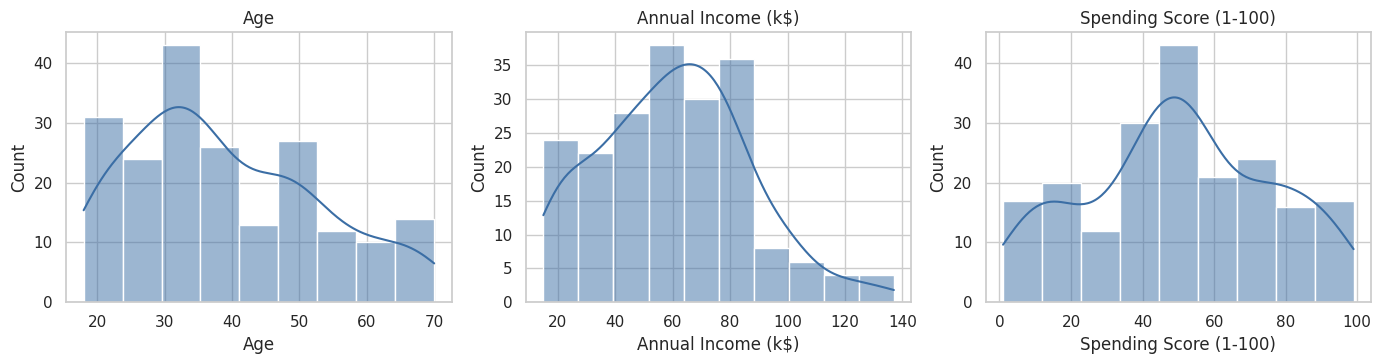

In [52]:
FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, c in zip(ax, FEATURES):
    sns.histplot(df[c], kde=True, ax=a, color="#3b6ea5")
    a.set_title(c)
save_show("01_feature_distributions")

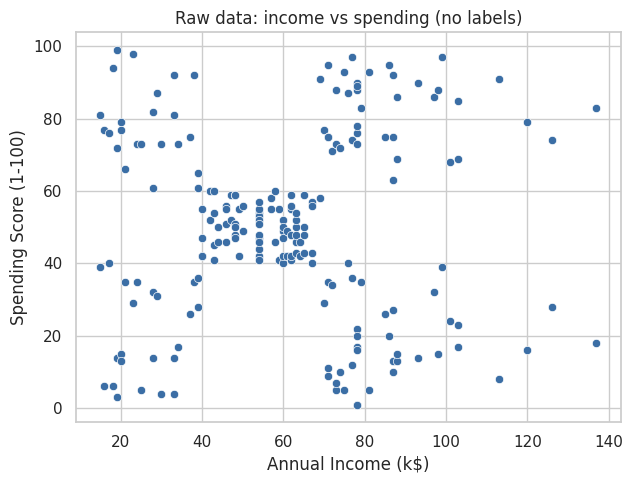

In [53]:
plt.figure(figsize=(6.5, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", color="#3b6ea5")
plt.title("Raw data: income vs spending (no labels)")
save_show("02_raw_scatter")

**Why scale?** K-means uses Euclidean distance, so a feature with a bigger range (income, up to ~140) would dominate a smaller one (age). `StandardScaler` puts every feature on the same footing.

In [54]:
X = df[FEATURES].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled mean ≈", X_scaled.mean(axis=0).round(3), "| std ≈", X_scaled.std(axis=0).round(3))

Scaled mean ≈ [-0. -0. -0.] | std ≈ [1. 1. 1.]


## 4. Baseline model
A plain K-means with a guessed K=3, random initialization and a single run. This is our "before optimization" reference point.

In [55]:
base = KMeans(n_clusters=3, init="random", n_init=1, random_state=SEED).fit(X_scaled)
baseline = {
    "Inertia (loss)": base.inertia_,
    "Silhouette": silhouette_score(X_scaled, base.labels_),
    "Davies-Bouldin": davies_bouldin_score(X_scaled, base.labels_),
    "Calinski-Harabasz": calinski_harabasz_score(X_scaled, base.labels_),
}
print("BASELINE (K=3, random init, n_init=1)")
for k, v in baseline.items():
    print(f"  {k:18s}: {v:.4f}")

BASELINE (K=3, random init, n_init=1)
  Inertia (loss)    : 297.0028
  Silhouette        : 0.3503
  Davies-Bouldin    : 1.0424
  Calinski-Harabasz : 100.4880


## 5. Loss function and "accuracy" graphs
K-means has no labels, so there is no classification accuracy. The equivalents are:
- **Loss function = inertia** (WCSS): sum of squared distances from points to their centroid. Lower is better.
- **Accuracy-like score = silhouette score** (−1 to 1). Higher is better.

### 5a. Loss vs iterations (convergence)

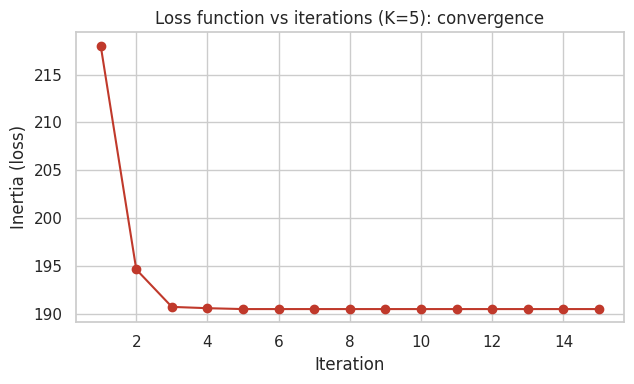

In [56]:
losses = []
for it in range(1, 16):
    m = KMeans(n_clusters=5, init="random", n_init=1, max_iter=it, tol=0, random_state=SEED).fit(X_scaled)
    losses.append(m.inertia_)
plt.figure(figsize=(6.5, 4))
plt.plot(range(1, 16), losses, marker="o", color="#c0392b")
plt.xlabel("Iteration"); plt.ylabel("Inertia (loss)")
plt.title("Loss function vs iterations (K=5): convergence")
save_show("03_loss_vs_iterations")

### 5b. Elbow method and silhouette for K = 2..10

    K   Inertia  Silhouette  Davies-Bouldin
0   2  389.3862      0.3355          1.2607
1   3  295.2122      0.3578          1.0503
2   4  205.2251      0.4040          0.9308
3   5  168.2476      0.4166          0.8746
4   6  133.8684      0.4284          0.8254
5   7  117.0116      0.4172          0.7935
6   8  103.8733      0.4082          0.8918
7   9   93.0929      0.4177          0.8198
8  10   82.3852      0.4066          0.8679


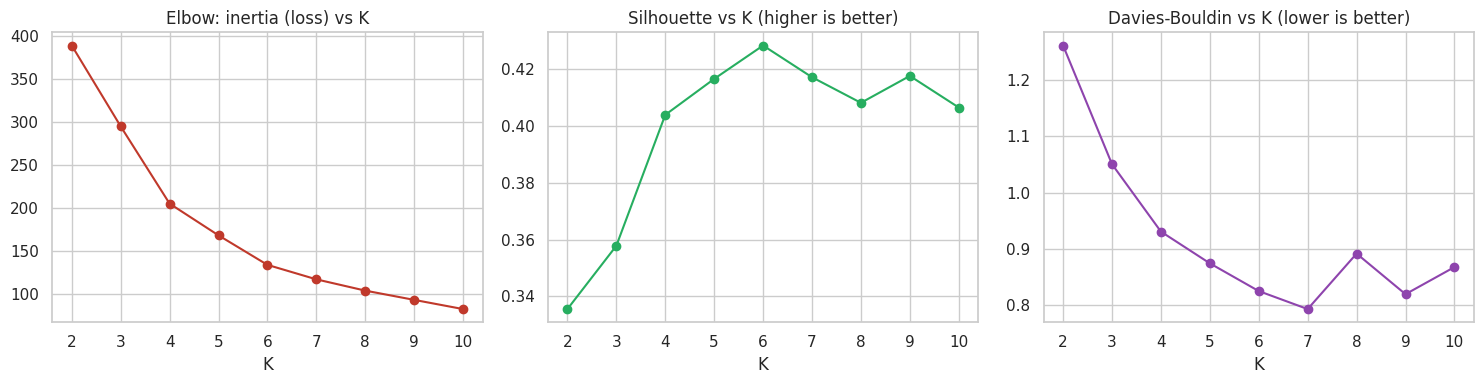

Best K by silhouette: 6


In [57]:
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    m = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(X_scaled)
    rows.append({"K": k, "Inertia": m.inertia_,
                 "Silhouette": silhouette_score(X_scaled, m.labels_),
                 "Davies-Bouldin": davies_bouldin_score(X_scaled, m.labels_)})
kdf = pd.DataFrame(rows)
display(kdf.round(4)) if "display" in globals() else print(kdf.round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(kdf.K, kdf.Inertia, marker="o", color="#c0392b"); ax[0].set_title("Elbow: inertia (loss) vs K")
ax[1].plot(kdf.K, kdf.Silhouette, marker="o", color="#27ae60"); ax[1].set_title("Silhouette vs K (higher is better)")
ax[2].plot(kdf.K, kdf["Davies-Bouldin"], marker="o", color="#8e44ad"); ax[2].set_title("Davies-Bouldin vs K (lower is better)")
for a in ax: a.set_xlabel("K")
save_show("04_elbow_silhouette")

best_k_sil = int(kdf.loc[kdf.Silhouette.idxmax(), "K"])
print("Best K by silhouette:", best_k_sil)

## 6. Optimization
K-means has no activation functions or optimizers like a neural network, so the equivalent levers are:

| Idea from assignment | K-means equivalent used here |
|---|---|
| Change optimizer | initialization (`random` vs `k-means++`) and solver (`lloyd` vs `elkan`) |
| Fine-tuning / hyper-parameters | K, `n_init`, `max_iter` via grid search |
| Data augmentation / preprocessing | feature scaling, feature choice, outlier check |
| Check overfitting / underfitting | train vs held-out test (Section 7) |

In [58]:
import itertools, time
grid = {
    "n_clusters": list(range(3, 9)),
    "init": ["random", "k-means++"],
    "n_init": [1, 10, 30],
    "algorithm": ["lloyd", "elkan"],
}
res = []
for k, init, ninit, algo in itertools.product(*grid.values()):
    t = time.time()
    m = KMeans(n_clusters=k, init=init, n_init=ninit, algorithm=algo, random_state=SEED).fit(X_scaled)
    res.append({"K": k, "init": init, "n_init": ninit, "algorithm": algo,
                "inertia": m.inertia_, "silhouette": silhouette_score(X_scaled, m.labels_),
                "davies_bouldin": davies_bouldin_score(X_scaled, m.labels_), "time_s": time.time() - t})
gs = pd.DataFrame(res).sort_values("silhouette", ascending=False).reset_index(drop=True)
print("Top 8 configurations:")
print(gs.head(8).round(4).to_string())
best = gs.iloc[0]

Top 8 configurations:
   K       init  n_init algorithm   inertia  silhouette  davies_bouldin  time_s
0  6  k-means++       1     elkan  134.3528      0.4311          0.8350  0.0148
1  6  k-means++       1     lloyd  134.3528      0.4311          0.8350  0.0151
2  6     random      30     elkan  133.8684      0.4284          0.8254  0.6815
3  6     random      30     lloyd  133.8684      0.4284          0.8254  0.0836
4  6  k-means++      10     lloyd  133.8684      0.4284          0.8254  0.0533
5  6  k-means++      10     elkan  133.8684      0.4284          0.8254  0.0950
6  6  k-means++      30     lloyd  133.8683      0.4274          0.8277  0.1696
7  6  k-means++      30     elkan  133.8683      0.4274          0.8277  0.3321


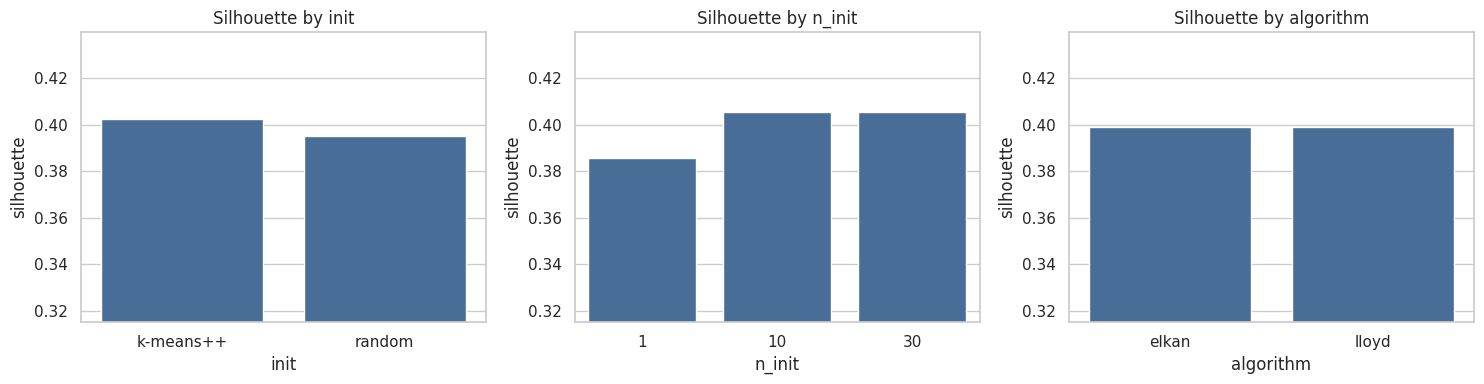

In [59]:
# Effect of each choice on silhouette (averaged over the rest of the grid)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["init", "n_init", "algorithm"]):
    sns.barplot(data=gs, x=col, y="silhouette", ax=a, color="#3b6ea5", errorbar=None)
    a.set_title(f"Silhouette by {col}")
    a.set_ylim(gs.silhouette.min() * 0.9, gs.silhouette.max() * 1.02)
save_show("05_tuning_effects")

### Before vs after optimization

In [60]:
final_k = int(best.K)
opt = KMeans(n_clusters=final_k, init=best.init, n_init=int(best.n_init), algorithm=best.algorithm, random_state=SEED).fit(X_scaled)
after = {"Inertia (loss)": opt.inertia_, "Silhouette": silhouette_score(X_scaled, opt.labels_),
         "Davies-Bouldin": davies_bouldin_score(X_scaled, opt.labels_),
         "Calinski-Harabasz": calinski_harabasz_score(X_scaled, opt.labels_)}
cmp = pd.DataFrame({"Baseline": baseline, "Optimized": after})
cmp["Better?"] = ["lower" if i in ("Inertia (loss)", "Davies-Bouldin") else "higher" for i in cmp.index]
print(f"Chosen: K={final_k}, init={best.init}, n_init={int(best.n_init)}, algorithm={best.algorithm}")
print(cmp.round(4).to_string())

Chosen: K=6, init=k-means++, n_init=1, algorithm=elkan
                   Baseline  Optimized Better?
Inertia (loss)     297.0028   134.3528   lower
Silhouette           0.3503     0.4311  higher
Davies-Bouldin       1.0424     0.8350   lower
Calinski-Harabasz  100.4880   134.4752  higher


## 7. Overfitting / underfitting check
Clustering has no labels, so we split the data 70/30. We **fit on train only**, then measure on both train and unseen test points:
- **Underfitting:** K too small → high loss on both sets, low silhouette.
- **Overfitting:** K too large → train loss keeps falling, but the test loss / silhouette stops improving or gets worse, and clusters become unstable.

We also check **stability**: refit on two different bootstrap samples and compare labels with Adjusted Rand Index (1.0 = identical).

 K  train_loss  test_loss  train_sil  test_sil  stability_ARI
 2      2.0770     1.6491     0.3269    0.3525         0.7470
 3      1.5447     1.4620     0.3503    0.3437         0.9413
 4      1.0619     0.9629     0.4114    0.3784         0.7372
 5      0.8517     0.8458     0.4228    0.3849         0.8113
 6      0.6825     0.6789     0.4287    0.4066         1.0000
 7      0.6172     0.5561     0.3944    0.4329         0.6370
 8      0.5501     0.5249     0.4041    0.4528         0.7519
 9      0.4799     0.4692     0.4170    0.4160         0.5960
10      0.4407     0.4252     0.3766    0.3922         0.8158
11      0.3815     0.3852     0.3924    0.4116         0.6702
12      0.3445     0.3642     0.3764    0.3457         0.8310


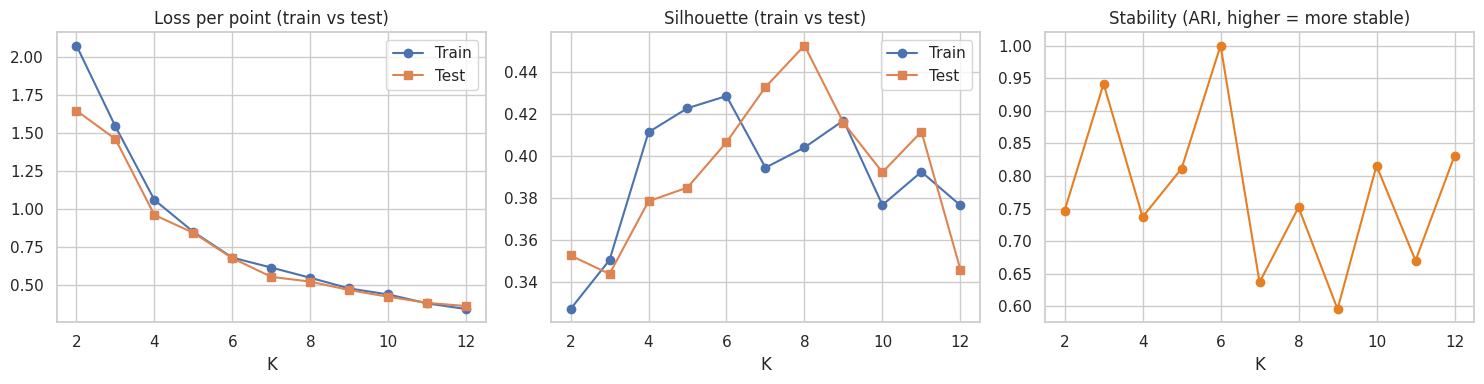

In [61]:
Xtr, Xte = train_test_split(X_scaled, test_size=0.3, random_state=SEED)
chk = []
for k in range(2, 13):
    m = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(Xtr)
    tr_loss = m.inertia_ / len(Xtr)
    te_loss = -m.score(Xte) / len(Xte)     # score() = -inertia on new data
    tr_sil = silhouette_score(Xtr, m.labels_)
    te_sil = silhouette_score(Xte, m.predict(Xte))
    # stability on two bootstrap samples
    r = np.random.RandomState(k)
    a = Xtr[r.choice(len(Xtr), len(Xtr))]; b = Xtr[r.choice(len(Xtr), len(Xtr))]
    ma = KMeans(n_clusters=k, n_init=10, random_state=1).fit(a); mb = KMeans(n_clusters=k, n_init=10, random_state=2).fit(b)
    ari = adjusted_rand_score(ma.predict(Xte), mb.predict(Xte))
    chk.append({"K": k, "train_loss": tr_loss, "test_loss": te_loss, "train_sil": tr_sil, "test_sil": te_sil, "stability_ARI": ari})
chk = pd.DataFrame(chk)
print(chk.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(chk.K, chk.train_loss, marker="o", label="Train"); ax[0].plot(chk.K, chk.test_loss, marker="s", label="Test")
ax[0].set_title("Loss per point (train vs test)"); ax[0].legend()
ax[1].plot(chk.K, chk.train_sil, marker="o", label="Train"); ax[1].plot(chk.K, chk.test_sil, marker="s", label="Test")
ax[1].set_title("Silhouette (train vs test)"); ax[1].legend()
ax[2].plot(chk.K, chk.stability_ARI, marker="o", color="#e67e22"); ax[2].set_title("Stability (ARI, higher = more stable)")
for a in ax: a.set_xlabel("K")
save_show("06_overfit_underfit")

**Reading the graphs:**
- **Loss:** train and test loss fall together and stay close for every K, so there is no big train/test gap (no strong overfitting from the loss).
- **Underfitting:** at K=2-3 the loss is high and the silhouette is low, so the model is too simple.
- **Silhouette:** on the training data it is highest at K=6. The test silhouette is noisier because the test set is small (60 points), so it is not over-read. It falls again for large K (about K≥9), a sign that extra clusters only split real groups.
- **Stability:** K=6 gave identical clusters on two different resamples (ARI = 1.0), which supports choosing K=6.

## 8. Final model and segment interpretation

In [62]:
df["Cluster"] = opt.labels_
centers = pd.DataFrame(scaler.inverse_transform(opt.cluster_centers_), columns=FEATURES).round(1)
centers["Customers"] = df.Cluster.value_counts().sort_index().values
centers.index.name = "Cluster"
print(centers.to_string())

          Age  Annual Income (k$)  Spending Score (1-100)  Customers
Cluster                                                             
0        56.3                54.3                    49.1         45
1        32.7                86.5                    82.1         39
2        25.6                26.5                    76.2         25
3        26.1                59.4                    44.4         40
4        44.0                90.1                    17.9         30
5        45.5                26.3                    19.4         21


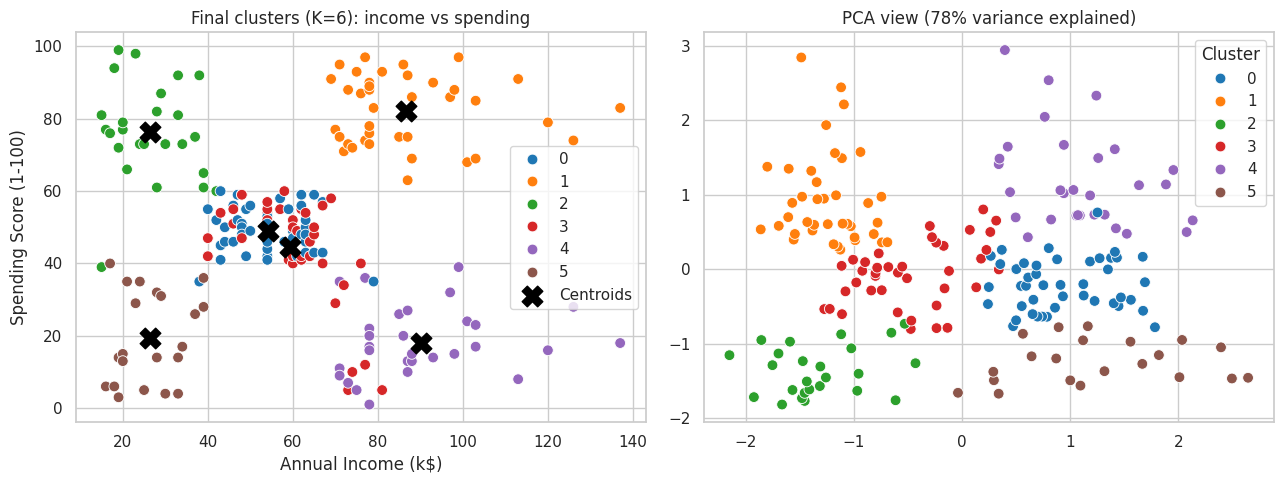

In [63]:
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(X_scaled)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)", hue="Cluster", palette="tab10", s=60, ax=ax[0])
cc = scaler.inverse_transform(opt.cluster_centers_)
ax[0].scatter(cc[:, 1], cc[:, 2], c="black", marker="X", s=220, label="Centroids")
ax[0].set_title(f"Final clusters (K={final_k}): income vs spending"); ax[0].legend()
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df.Cluster, palette="tab10", s=60, ax=ax[1])
ax[1].set_title(f"PCA view ({pca.explained_variance_ratio_.sum():.0%} variance explained)")
save_show("07_final_clusters")

### Business meaning of each segment
Name each cluster from its centroid values in the table above. For the Mall Customers data the typical segments are:
- **High income, high spending**: premium target customers, loyalty offers
- **High income, low spending**: under-served, personalized promotions
- **Low income, high spending**: young trend-driven shoppers, discounts and deals
- **Low income, low spending**: price-sensitive, low priority
- **Average income, average spending**: core customers, steady engagement

(Check the printed centroids; label your own clusters accordingly.)

## 9. Conclusion
- Scaling the data and choosing K=6 (elbow + silhouette + train/test check) gave a clearly better model than the K=3 baseline: loss fell from about 297 to 134 and silhouette rose from 0.350 to 0.431.
- Choosing K mattered far more than the other settings: all top grid-search configurations scored within about 0.004 silhouette of each other, so initialization, `n_init` and solver only had a small effect on this small, well-separated dataset.
- Limits: K-means assumes round, similar-sized clusters and is sensitive to outliers and to the features chosen. The dataset has only 200 customers.
- Next steps: try DBSCAN / Gaussian Mixtures, add more features (e.g. purchase history).

In [64]:
df.to_csv("results/customers_with_clusters.csv", index=False)
cmp.to_csv("results/baseline_vs_optimized.csv")
gs.to_csv("results/tuning_grid.csv", index=False)
print("Saved results/")

Saved results/
